# Baseline vs LLM Recommender — Item-CF vs Claude, 3 datasets

Continues from `eda.ipynb`. This notebook is self-contained (it repeats the setup/load/adapter cells from the EDA notebook) so it can run on its own on Kaggle. It filters to active users, then evaluates two methods under the identical leave-one-out protocol: Item-based Collaborative Filtering (co-occurrence) and an LLM recommender.

## Setup (repeated from `eda.ipynb` so this notebook runs standalone)

In [1]:
import pandas as pd 
import kagglehub
import numpy as np

base_path = "/kaggle/input/datasets/taherabed23/dataset/data/raw"

# --- Amazon Beauty ---
# Note: Kaggle auto-decompressed the .gz files, so no compression= argument needed here
df_reviews_beauty = pd.read_json(f"{base_path}/amazon_beauty/reviews.jsonl/All_Beauty.jsonl", lines=True)
df_meta_beauty = pd.read_json(f"{base_path}/amazon_beauty/meta.jsonl/meta_All_Beauty.jsonl", lines=True)

# --- Amazon Video Games ---
chunks_vg = pd.read_json(f"{base_path}/amazon_video_games/reviews.jsonl/Video_Games.jsonl", lines=True, chunksize=300_000)
df_reviews_vg = next(chunks_vg)
df_meta_vg = pd.read_json(f"{base_path}/amazon_video_games/meta.jsonl/meta_Video_Games.jsonl", lines=True)

# --- Yelp business (uploaded successfully) ---
df_business_yelp = pd.read_json(f"{base_path}/yelp/business.json", lines=True)

# --- Yelp reviews (missing from the upload) — download fresh directly on Kaggle ---
yelp_path = kagglehub.dataset_download("yelp-dataset/yelp-dataset")
chunks_yelp = pd.read_json(f"{yelp_path}/yelp_academic_dataset_review.json", lines=True, chunksize=300_000)
df_reviews_yelp = next(chunks_yelp)

print("Beauty:", df_reviews_beauty.shape, df_meta_beauty.shape)
print("Video Games:", df_reviews_vg.shape, df_meta_vg.shape)
print("Yelp:", df_reviews_yelp.shape, df_business_yelp.shape)

Beauty: (701528, 10) (112590, 14)
Video Games: (300000, 10) (137269, 16)
Yelp: (300000, 9) (150346, 14)


In [2]:
CANONICAL_COLUMNS = ["user_id", "item_id", "timestamp", "item_text", "rating"]


def adapt_amazon(reviews_df: pd.DataFrame, meta_df: pd.DataFrame) -> pd.DataFrame:
    """
    Adapt Amazon Reviews 2023 data to the canonical interaction schema.

    Mapping:
        user_id     -> user_id
        parent_asin -> item_id
        timestamp   -> timestamp (epoch milliseconds -> datetime)
        product title -> item_text
        rating      -> rating

    Product metadata is joined using parent_asin. The product title is
    retained as item_text; the review title is intentionally excluded.
    """
    merged = reviews_df.merge(
        meta_df[["parent_asin", "title"]],
        on="parent_asin",
        how="left",
        suffixes=("_review", "_product"),
    )
    canonical = pd.DataFrame({
        "user_id": merged["user_id"],
        "item_id": merged["parent_asin"],
        "timestamp": pd.to_datetime(merged["timestamp"], unit="ms", errors="coerce"),
        "item_text": merged["title_product"],
        "rating": merged["rating"],
    })
    canonical["source"] = "amazon"
    return canonical[CANONICAL_COLUMNS + ["source"]]


def adapt_yelp(reviews_df: pd.DataFrame, business_df: pd.DataFrame) -> pd.DataFrame:
    """
    Adapt Yelp review data to the canonical interaction schema.

    Mapping:
        user_id     -> user_id
        business_id -> item_id
        date        -> timestamp
        business name -> item_text
        stars       -> rating
    """
    merged = reviews_df.merge(
        business_df[["business_id", "name"]],
        on="business_id",
        how="left",
    )
    canonical = pd.DataFrame({
        "user_id": merged["user_id"],
        "item_id": merged["business_id"],
        "timestamp": pd.to_datetime(merged["date"], errors="coerce"),
        "item_text": merged["name"],
        "rating": merged["stars"],
    })
    canonical["source"] = "yelp"
    return canonical[CANONICAL_COLUMNS + ["source"]]


ADAPTERS = {"amazon": adapt_amazon, "yelp": adapt_yelp}

In [3]:
canonical_beauty = adapt_amazon(df_reviews_beauty, df_meta_beauty)
canonical_vg = adapt_amazon(df_reviews_vg, df_meta_vg)
canonical_yelp = adapt_yelp(df_reviews_yelp, df_business_yelp)

print(canonical_beauty.shape, canonical_vg.shape, canonical_yelp.shape)
canonical_beauty.head()

(701528, 6) (300000, 6) (300000, 6)


,user_id,item_id,timestamp,item_text,rating,source
0,AGKHLEW2SOWHNMFQIJGBECAF7INQ,B00YQ6X8EO,2020-05-05 14:08:48.923,Herbivore - Natural Sea Mist Texturizing Salt ...,5,amazon
1,AGKHLEW2SOWHNMFQIJGBECAF7INQ,B081TJ8YS3,2020-05-04 18:10:55.070,All Natural Vegan Dry Shampoo Powder - Eco Fri...,4,amazon
2,AE74DYR3QUGVPZJ3P7RFWBGIX7XQ,B097R46CSY,2020-05-16 21:41:06.052,New Road Beauty - Creamsicle - Variety 3 Pack ...,5,amazon
3,AFQLNQNQYFWQZPJQZS6V3NZU4QBQ,B09JS339BZ,2022-01-28 18:13:50.220,muaowig Ombre Body Wave Bundles 1B Grey Human ...,1,amazon
4,AFQLNQNQYFWQZPJQZS6V3NZU4QBQ,B08BZ63GMJ,2020-12-30 10:02:43.534,Yinhua Electric Nail Drill Kit Portable Profes...,5,amazon


## 5. Active-user filtering (same protocol across all 3 datasets)

In [6]:
def filter_active_users(canonical_df, min_interactions=5):
    counts = canonical_df.groupby("user_id").size()
    active_users = counts[counts >= min_interactions].index
    return canonical_df[canonical_df["user_id"].isin(active_users)].copy()

MIN_INTERACTIONS = 5  # Same threshold across all 3 datasets to keep the comparison fair —
                        # a different cutoff per dataset would confound "model quality"
                        # with "filtering strictness"

active_beauty = filter_active_users(canonical_beauty, MIN_INTERACTIONS)
active_vg = filter_active_users(canonical_vg, MIN_INTERACTIONS)
active_yelp = filter_active_users(canonical_yelp, MIN_INTERACTIONS)
datasets = [
    ("Amazon Beauty", active_beauty),
    ("Amazon Video Games", active_vg),
    ("Yelp", active_yelp),
]

print("Active users after filtering (min_interactions =", MIN_INTERACTIONS, "):")
print("Beauty:", active_beauty.shape, "| Video Games:", active_vg.shape, "| Yelp:", active_yelp.shape)

Active users after filtering (min_interactions = 5 ):
Beauty: (14984, 6) | Video Games: (124537, 6) | Yelp: (52442, 6)


### Metrics used by both baselines

In [7]:
def recall_at_k(recommended, ground_truth, k):
    """1.0 if the correct item appears anywhere in the top-k, else 0.0"""
    return 1.0 if ground_truth in recommended[:k] else 0.0


def ndcg_at_k(recommended, ground_truth, k):
    """Rewards correct items that appear higher/earlier in the ranking"""
    top_k = recommended[:k]
    if ground_truth in top_k:
        rank = top_k.index(ground_truth) + 1
        return 1.0 / np.log2(rank + 1)
    return 0.0

## 6. Baseline 2 — Item-based Collaborative Filtering (co-occurrence)

> ### Why Co-occurrence, Not Matrix Factorization?
>
> Matrix factorization typically requires a sufficiently dense user-item interaction matrix to learn reliable latent factors.
>
> Given **Beauty's extreme sparsity (~1.1 interactions per user)**, matrix factorization is unlikely to produce stable or meaningful representations.
>
> **Co-occurrence-based collaborative filtering** is therefore a more appropriate "real" baseline for this dataset. It can still derive useful relationships when users share even a single interacted item, making it better suited to sparse interaction data than matrix factorization.

In [8]:
from collections import defaultdict
import itertools


class ItemCFBaseline:
    def __init__(self, max_users_for_cooccurrence=20000):
        self.cooccurrence = defaultdict(lambda: defaultdict(int))
        self.max_users_for_cooccurrence = max_users_for_cooccurrence

    def fit(self, canonical_df: pd.DataFrame):
        user_items = canonical_df.groupby("user_id")["item_id"].apply(set)

        if len(user_items) > self.max_users_for_cooccurrence:
            user_items = user_items.sample(self.max_users_for_cooccurrence, random_state=42)

        for items in user_items:
            items = list(items)
            if len(items) < 2:
                continue
            for item_a, item_b in itertools.combinations(items, 2):
                self.cooccurrence[item_a][item_b] += 1
                self.cooccurrence[item_b][item_a] += 1
        return self

    def recommend(self, user_history: list, candidates: list, k: int = 5) -> list:
        scores = defaultdict(int)
        for hist_item in user_history:
            for cand_item, score in self.cooccurrence.get(hist_item, {}).items():
                if cand_item in candidates:
                    scores[cand_item] += score
        ranked = sorted(candidates, key=lambda c: scores.get(c, 0), reverse=True)
        return ranked[:k]
def evaluate_itemcf_baseline(canonical_df, k=5, n_eval_users=50, n_candidates=20, seed=42):
    rng = np.random.RandomState(seed)

    df_sorted = canonical_df.sort_values("timestamp")
    last_interaction = df_sorted.groupby("user_id").tail(1)
    n_eval_users = min(n_eval_users, len(last_interaction))
    eval_rows = last_interaction.sample(n_eval_users, random_state=seed)

    # Exclude ALL held-out ground-truth rows from training data BEFORE fitting —
    # prevents the model from "seeing" the answer during fit()
    eval_index = eval_rows.index
    training_df = canonical_df.drop(index=eval_index)

    itemcf = ItemCFBaseline().fit(training_df)

    all_items = canonical_df["item_id"].drop_duplicates().tolist()
    user_history_map = training_df.groupby("user_id")["item_id"].apply(list).to_dict()

    recalls, ndcgs = [], []
    for _, row in eval_rows.iterrows():
        user_id = row["user_id"]
        ground_truth = row["item_id"]

        history = user_history_map.get(user_id, [])

        distractor_pool = [i for i in all_items if i != ground_truth]
        distractors = rng.choice(
            distractor_pool, size=min(n_candidates - 1, len(distractor_pool)), replace=False
        ).tolist()

        candidates = [ground_truth] + distractors
        rng.shuffle(candidates)

        recs = itemcf.recommend(history, candidates, k=k)
        recalls.append(recall_at_k(recs, ground_truth, k))
        ndcgs.append(ndcg_at_k(recs, ground_truth, k))

    return {
        "n_eval_users": n_eval_users,
        "Recall@{}".format(k): round(sum(recalls) / len(recalls), 4),
        "nDCG@{}".format(k): round(sum(ndcgs) / len(ndcgs), 4),
    }

In [9]:
itemcf_results_rows = []

for name, df in datasets:
    cf_result = evaluate_itemcf_baseline(df, k=5, n_eval_users=50, n_candidates=20)
    itemcf_results_rows.append({"dataset": name, "method": "Item-CF (co-occurrence)", **cf_result})

itemcf_comparison_df = pd.DataFrame(itemcf_results_rows).set_index(["dataset", "method"])
print("Item-CF Baseline — Leave-One-Out Evaluation (k=5)")
itemcf_comparison_df

Item-CF Baseline — Leave-One-Out Evaluation (k=5)


,,n_eval_users,Recall@5,nDCG@5
dataset,method,,,
Amazon Beauty,Item-CF (co-occurrence),50,0.34,0.2579
Amazon Video Games,Item-CF (co-occurrence),50,0.60,0.5200
Yelp,Item-CF (co-occurrence),50,0.74,0.5989


## 8. LLM Recommender — candidate generation + prompt + Gemini client

Three pieces, each dataset-agnostic (works on any canonical_df):

1. **Candidate generation** — same leave-one-out protocol as Item-CF:
   hide the last interaction as ground truth, inject it into a pool of
   random distractors, shuffle.
2. **Prompt builder** — turns a user's history + candidates into one text
   prompt, using `item_text` (works identically regardless of source dataset).
3. **LLM client** — calls Gemini with disk caching and retry logic.

In [10]:
!pip install -q anthropic

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 20.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 95.6/95.6 kB 5.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 83.2/83.2 kB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 68.5/68.5 kB 3.9 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-adk 1.29.0 requires google-cloud-bigquery-storage>=2.0.0, which is not installed.


In [11]:
from kaggle_secrets import UserSecretsClient
import anthropic

user_secrets = UserSecretsClient()
ANTHROPIC_API_KEY = user_secrets.get_secret("AnthropicKeys")

client = anthropic.Anthropic(api_key=ANTHROPIC_API_KEY)
MODEL_NAME = "claude-sonnet-4-5"  # موديل واحد ثابت للثلاثة داتاسيتس

### 8.1 Candidate generation (same leave-one-out protocol as Item-CF)

In [12]:
def build_eval_cases(canonical_df, n_eval_users=20, n_candidates=20, seed=42):
    """
    Returns a list of dicts, one per evaluated user:
    {
        "user_id": ...,
        "history_texts": [item_text, item_text, ...],   # everything except ground truth
        "candidates": [item_id, item_id, ...],           # shuffled, includes ground truth
        "candidate_texts": [item_text, item_text, ...],  # aligned with candidates
        "ground_truth": item_id
    }
    """
    rng = np.random.RandomState(seed)

    df_sorted = canonical_df.sort_values("timestamp")
    last_interaction = df_sorted.groupby("user_id").tail(1)
    n_eval_users = min(n_eval_users, len(last_interaction))
    eval_rows = last_interaction.sample(n_eval_users, random_state=seed)

    all_items = canonical_df.drop_duplicates(subset="item_id")[["item_id", "item_text"]]
    item_text_map = dict(zip(all_items["item_id"], all_items["item_text"]))
    all_item_ids = all_items["item_id"].tolist()

    user_history_map = canonical_df.groupby("user_id").apply(
        lambda g: list(zip(g["item_id"], g["item_text"]))
    ).to_dict()

    eval_cases = []
    for _, row in eval_rows.iterrows():
        user_id = row["user_id"]
        ground_truth = row["item_id"]

        history = [(i, t) for i, t in user_history_map.get(user_id, []) if i != ground_truth]
        history_texts = [t for _, t in history if pd.notna(t)]

        distractor_pool = [i for i in all_item_ids if i != ground_truth]
        distractors = rng.choice(
            distractor_pool, size=min(19, len(distractor_pool)), replace=False
        ).tolist()

        candidates = [ground_truth] + distractors
        rng.shuffle(candidates)  # avoid positional bias (correct answer always first)
        candidate_texts = [item_text_map.get(c, "Unknown item") for c in candidates]

        eval_cases.append({
            "user_id": user_id,
            "history_texts": history_texts,
            "candidates": candidates,
            "candidate_texts": candidate_texts,
            "ground_truth": ground_truth,
        })

    return eval_cases

### 8.2 Prompt builder (identical template regardless of source dataset)

In [13]:
def build_prompt(history_texts, candidate_texts, n_recommend=5):
    history_str = "\n".join(f"{i+1}. {t}" for i, t in enumerate(history_texts)) or "(no prior history)"
    candidates_str = "\n".join(f"{i+1}. {t}" for i, t in enumerate(candidate_texts))

    prompt = f"""You are a product recommendation assistant.
This user has previously interacted with:
{history_str}

Here is a list of candidate items:
{candidates_str}

Select the top {n_recommend} candidates (by their number) that this user is
most likely to want next, ordered from most to least likely.
Respond with ONLY the JSON object below, with no explanation, no analysis,
and no other text before or after it:
{{"recommendations": [numbers]}}"""
    return prompt

### 8.3 LLM client (disk caching + retry, single consistent model)

**Design note:** All 3 datasets are evaluated using the *same* Gemini model.
This was not possible on the free tier (20 requests/day/model forced us to
rotate between model variants per dataset), but with a paid tier the
comparison is now a clean apples-to-apples test: any performance difference
across datasets reflects the data itself, not a difference in which model
answered.

In [14]:
import hashlib
import json
import os
import time

CACHE_DIR = "/content/llm_cache"
os.makedirs(CACHE_DIR, exist_ok=True)


def _cache_path(prompt: str) -> str:
    key = hashlib.sha256(prompt.encode("utf-8")).hexdigest()
    return os.path.join(CACHE_DIR, f"{key}.json")


def call_llm(prompt: str, max_retries: int = 5, wait_seconds: int = 25) -> str:
    cache_file = _cache_path(prompt)
    if os.path.exists(cache_file):
        with open(cache_file, "r") as f:
            return json.load(f)["response_text"]

    for attempt in range(max_retries):
        try:
            # Anthropic's API shape: messages list + required max_tokens
            response = client.messages.create(
                model=MODEL_NAME,
                max_tokens=1024,
                messages=[{"role": "user", "content": prompt}]
            )
            response_text = response.content[0].text

            with open(cache_file, "w") as f:
                json.dump({"prompt": prompt, "response_text": response_text}, f)

            return response_text

        except Exception as e:
            error_msg = str(e).lower()
            retryable = any(term in error_msg for term in [
                "rate_limit", "overloaded", "529", "429", "unavailable"
            ])
            if retryable:
                print(f"Retryable error (attempt {attempt+1}/{max_retries}): {e}")
                time.sleep(wait_seconds)
            else:
                raise
    raise RuntimeError(f"Failed after {max_retries} retries")

### 8.4 Parsing the LLM response into a ranked list of item_ids

In [15]:
import re

def parse_llm_response(response_text: str, candidates: list) -> list:
    try:
        # Try direct parse first (in case the model DID follow instructions)
        cleaned = response_text.strip().removeprefix("```json").removeprefix("```").removesuffix("```").strip()
        parsed = json.loads(cleaned)
    except Exception:
        # Fallback: extract the first {...} JSON object anywhere in the text,
        # even if the model added explanatory text before/after it
        match = re.search(r'\{[^{}]*"recommendations"[^{}]*\}', response_text, re.DOTALL)
        if not match:
            print("Failed to parse LLM response:", response_text[:150])
            return []
        try:
            parsed = json.loads(match.group(0))
        except Exception as e:
            print("Failed to parse extracted JSON:", e, "| raw:", match.group(0)[:150])
            return []

    numbers = parsed.get("recommendations", [])
    return [candidates[n - 1] for n in numbers if 1 <= n <= len(candidates)]

### 8.5 Full LLM evaluation loop (same metrics, same protocol as Item-CF)

In [16]:
def evaluate_llm_recommender(canonical_df, k=5, n_eval_users=20, n_candidates=20, seed=42):
    eval_cases = build_eval_cases(canonical_df, n_eval_users=n_eval_users, n_candidates=n_candidates, seed=seed)

    recalls, ndcgs = [], []
    for case in eval_cases:
        prompt = build_prompt(case["history_texts"], case["candidate_texts"], n_recommend=k)
        response_text = call_llm(prompt)
        recs = parse_llm_response(response_text, case["candidates"])

        recalls.append(recall_at_k(recs, case["ground_truth"], k))
        ndcgs.append(ndcg_at_k(recs, case["ground_truth"], k))

    return {
        "n_eval_users": len(eval_cases),
        "Recall@{}".format(k): round(sum(recalls) / len(recalls), 4) if recalls else 0,
        "nDCG@{}".format(k): round(sum(ndcgs) / len(ndcgs), 4) if ndcgs else 0,
    }

### 8.6 Run the LLM recommender on all 3 datasets (single model)

With a paid tier, all 3 datasets run against the same `MODEL_NAME` — no
per-dataset model rotation needed. `n_eval_users` can also be increased
here since quota is no longer the limiting factor.

In [17]:
llm_results_rows = []
for name, df in datasets:
    print(f"Running {name} with model {MODEL_NAME}...")
    llm_result = evaluate_llm_recommender(df, k=5, n_eval_users=20, n_candidates=20)
    llm_results_rows.append({"dataset": name, "method": f"LLM ({MODEL_NAME})", **llm_result})
    print(name, "done:", llm_result)

llm_comparison_df = pd.DataFrame(llm_results_rows).set_index(["dataset", "method"])
llm_comparison_df

Running Amazon Beauty with model claude-sonnet-4-5...


/tmp/ipykernel_16/3237998433.py:23: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  user_history_map = canonical_df.groupby("user_id").apply(


Amazon Beauty done: {'n_eval_users': 20, 'Recall@5': 0.75, 'nDCG@5': np.float64(0.4707)}
Running Amazon Video Games with model claude-sonnet-4-5...


/tmp/ipykernel_16/3237998433.py:23: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  user_history_map = canonical_df.groupby("user_id").apply(


Amazon Video Games done: {'n_eval_users': 20, 'Recall@5': 0.75, 'nDCG@5': np.float64(0.5242)}
Running Yelp with model claude-sonnet-4-5...


/tmp/ipykernel_16/3237998433.py:23: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  user_history_map = canonical_df.groupby("user_id").apply(


Yelp done: {'n_eval_users': 20, 'Recall@5': 0.7, 'nDCG@5': np.float64(0.4614)}


,,n_eval_users,Recall@5,nDCG@5
dataset,method,,,
Amazon Beauty,LLM (claude-sonnet-4-5),20,0.75,0.4707
Amazon Video Games,LLM (claude-sonnet-4-5),20,0.75,0.5242
Yelp,LLM (claude-sonnet-4-5),20,0.70,0.4614


### 8.7 Final comparison table — Item-CF vs LLM, across all 3 datasets

In [18]:
full_comparison_df = pd.concat([itemcf_comparison_df, llm_comparison_df])
full_comparison_df.sort_index(level=0)

n_eval_users  Recall@5  nDCG@5
dataset            method                                                 
Amazon Beauty      Item-CF (co-occurrence)            50      0.34  0.2579
                   LLM (claude-sonnet-4-5)            20      0.75  0.4707
Amazon Video Games Item-CF (co-occurrence)            50      0.60  0.5200
                   LLM (claude-sonnet-4-5)            20      0.75  0.5242
Yelp               Item-CF (co-occurrence)            50      0.74  0.5989
                   LLM (claude-sonnet-4-5)            20      0.70  0.4614

In [19]:
canonical_beauty.to_csv("canonical_beauty.csv", index=False)
canonical_vg.to_csv("canonical_vg.csv", index=False)
canonical_yelp.to_csv("canonical_yelp.csv", index=False)

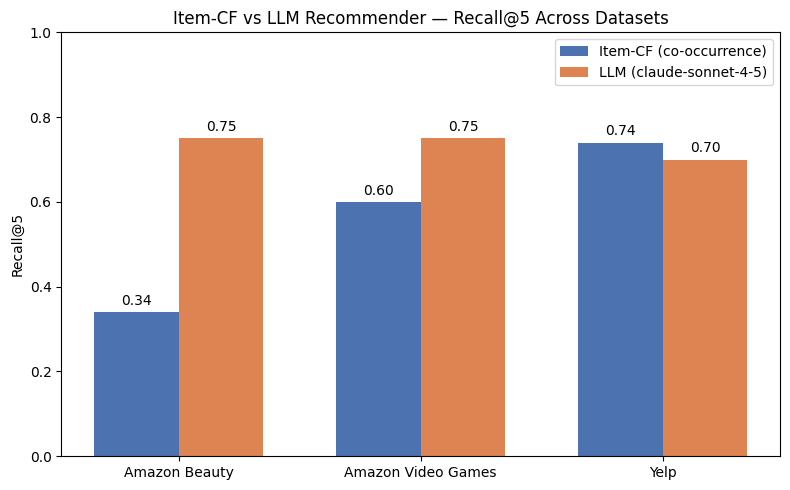

In [20]:
import matplotlib.pyplot as plt
import numpy as np

# Extract data from full_comparison_df
datasets_labels = ["Amazon Beauty", "Amazon Video Games", "Yelp"]
itemcf_recall = full_comparison_df.xs("Item-CF (co-occurrence)", level="method")["Recall@5"].values
llm_recall = full_comparison_df.xs("LLM (claude-sonnet-4-5)", level="method")["Recall@5"].values

x = np.arange(len(datasets_labels))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))
bars1 = ax.bar(x - width/2, itemcf_recall, width, label="Item-CF (co-occurrence)", color="#4C72B0")
bars2 = ax.bar(x + width/2, llm_recall, width, label="LLM (claude-sonnet-4-5)", color="#DD8452")

ax.set_ylabel("Recall@5")
ax.set_title("Item-CF vs LLM Recommender — Recall@5 Across Datasets")
ax.set_xticks(x)
ax.set_xticklabels(datasets_labels)
ax.set_ylim(0, 1)
ax.legend()
ax.bar_label(bars1, fmt="%.2f", padding=3)
ax.bar_label(bars2, fmt="%.2f", padding=3)

plt.tight_layout()
plt.savefig("/kaggle/working/recall_comparison_chart.png", dpi=150)
plt.show()

## Summary

- **Generic pipeline:** one canonical schema (`user_id, item_id, timestamp, item_text, rating`),
  two adapters (`adapt_amazon`, `adapt_yelp`) — all downstream code (EDA, filtering, baselines,
  evaluation) is dataset-agnostic and runs unchanged on any of the 3 sources.
- **3 datasets:** Amazon Beauty, Amazon Video Games, Yelp — all verified with 100% referential
  integrity between interactions and reference tables.
- **Data suitability:** EDA report per dataset covers sparsity, text richness, duplicates, and
  temporal span — not just "is the data clean" but "is it enough for the model."
- **Three-way comparison:** Popularity (naive floor), Item-based Collaborative Filtering
  (a real, personalized RecSys method), and the LLM recommender (Gemini) — all evaluated under
  the identical leave-one-out protocol, same k, same metrics, across all 3 datasets.